In [1]:
# Cell 1: Imports, student configuration, and dataset
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from IPython.display import Image, display

student_name = "Gualberto"
student_id = "TUPM-26-1130"
id_num = int(student_id[-3:])

color_bar = f"#{(id_num * 7) % 256:02x}{(id_num * 3) % 256:02x}{(id_num * 5) % 256:02x}"
color_line = f"#{(id_num * 2) % 256:02x}{(id_num * 9) % 256:02x}{(id_num * 4) % 256:02x}"

cmap_options = ['viridis', 'plasma', 'magma', 'inferno', 'coolwarm', 'YlOrRd']
cmap_color = cmap_options[id_num % len(cmap_options)]

dataset_path = Path("spotify_dataset") / "spotify_top_1000_tracks.csv"

df = pd.read_csv(dataset_path, encoding="utf-8")
df['track_name'] = df['track_name'].str.strip()
df['artist'] = df['artist'].str.strip()
df = df.drop_duplicates(subset=['track_name', 'artist'], keep='first')

df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['year'] = df['release_date'].dt.year

print("Student:", student_name, "|", student_id)
print("color_bar:", color_bar, "| color_line:", color_line, "| cmap_color:", cmap_color)
print("Rows loaded:", len(df))

Student: Gualberto | TUPM-26-1130
color_bar: #8e868a | color_line: #049208 | cmap_color: coolwarm
Rows loaded: 971


Top 10 Longest Tracks
                                         track_name                 artist  duration_min
1                                          Lost Boy                  Jaden      9.497883
2                                 I'm Getting Ready    Tasha Cobbs Leonard      8.436667
3                                           Mirrors      Justin Timberlake      8.069100
4   What Goes Around.../...Comes Around (Interlude)      Justin Timberlake      7.476217
5                                Achilles Come Down         Gang of Youths      7.035767
6                              Never Let Go (Of Me)                 Baltra      6.909833
7             House Of Balloons / Glass Table Girls             The Weeknd      6.753550
8                                              Stan                 Eminem      6.735100
9                                         Galvanize  The Chemical Brothers      6.563550
10                                      After Hours             The Weeknd      6.017100

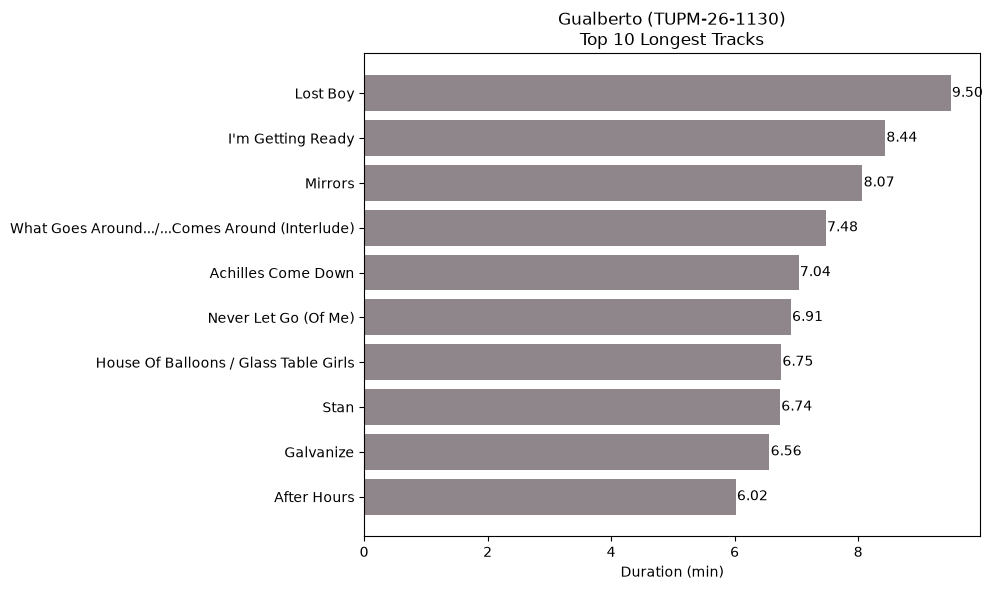

In [2]:
# Cell 2: Exercise 1 - Identify Longest Tracks
longest = (df.nlargest(10, 'duration_min')[['track_name', 'artist', 'duration_min']]
             .reset_index(drop=True))
longest.index = longest.index + 1

print("Top 10 Longest Tracks")
print(longest.to_string())

plt.figure(figsize=(10, 6))
positions = range(len(longest))
plt.barh(positions, longest['duration_min'], color=color_bar)
plt.yticks(positions, longest['track_name'])
plt.gca().invert_yaxis()

for pos, value in zip(positions, longest['duration_min']):
    plt.text(value + 0.02, pos, f"{value:.2f}", va='center')

plt.xlabel('Duration (min)')
plt.title(f"{student_name} ({student_id})\nTop 10 Longest Tracks")
plt.tight_layout()
plt.show()

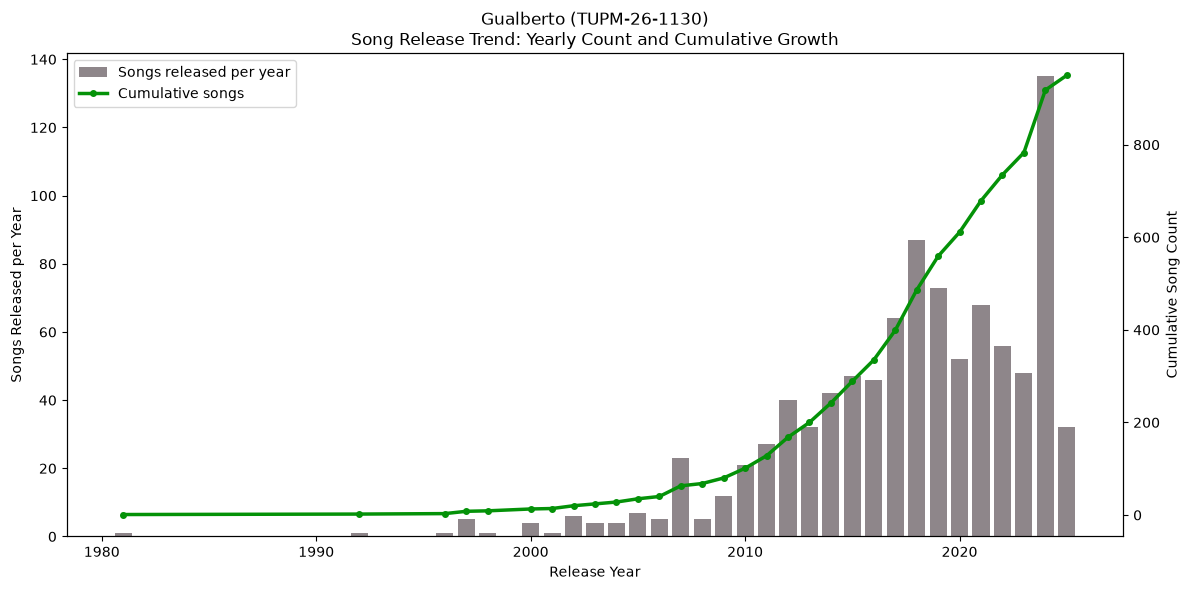

In [3]:
# Cell 3: Exercise 2 - Song Release Trend (bar + cumulative line)
yearly_df = df.dropna(subset=['year']).copy()
yearly_df['year'] = yearly_df['year'].astype(int)

yearly_counts = yearly_df.groupby('year').size()
cumulative_counts = yearly_counts.cumsum()

fig, ax1 = plt.subplots(figsize=(12, 6))

bars = ax1.bar(yearly_counts.index, yearly_counts.values, color=color_bar,
               label='Songs released per year')
ax1.set_xlabel('Release Year')
ax1.set_ylabel('Songs Released per Year')

ax2 = ax1.twinx()
line, = ax2.plot(cumulative_counts.index, cumulative_counts.values, color=color_line,
                 marker='o', markersize=4, linewidth=2.5, label='Cumulative songs')
ax2.set_ylabel('Cumulative Song Count')

ax1.legend([bars, line], ['Songs released per year', 'Cumulative songs'], loc='upper left')
plt.title(f"{student_name} ({student_id})\nSong Release Trend: Yearly Count and Cumulative Growth")
plt.tight_layout()
plt.show()

GIF saved successfully at: c:\Users\Admin\Lab8_Data_Visualization_Gualberto\hexbin_density_animation.gif


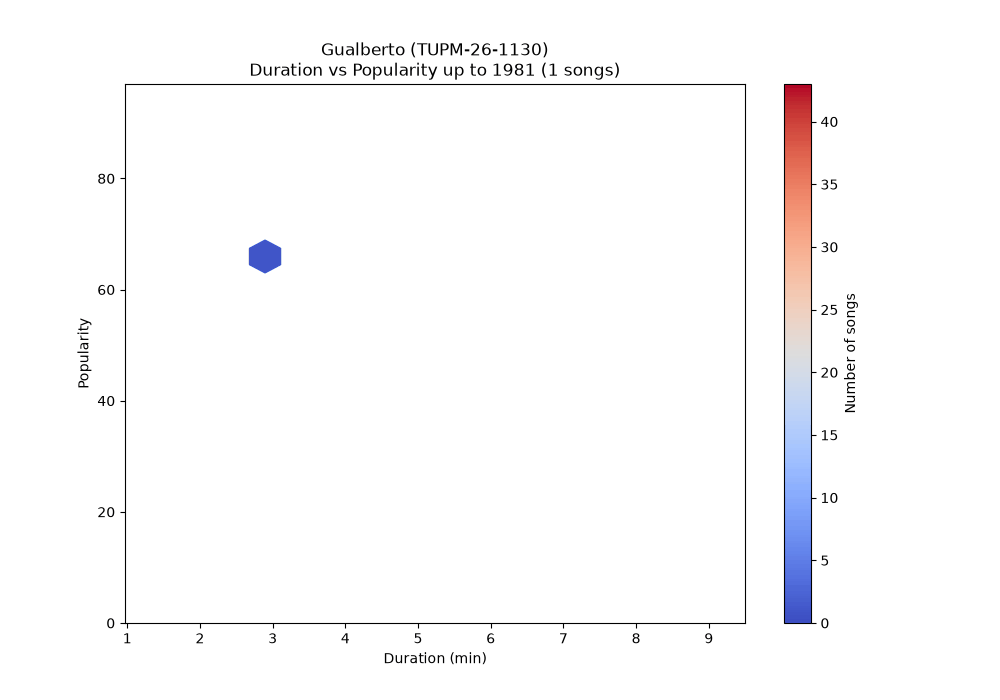

In [4]:
# Cell 4: Exercise 3 - Animated Hexbin Density Map of Duration vs Popularity
hex_df = df.dropna(subset=['year', 'duration_min', 'popularity']).copy()
hex_df['year'] = hex_df['year'].astype(int)

years = sorted(hex_df['year'].unique())

x_min, x_max = hex_df['duration_min'].min(), hex_df['duration_min'].max()
y_min, y_max = hex_df['popularity'].min(), hex_df['popularity'].max()
extent = (x_min, x_max, y_min, y_max)

# Fixed color scale so frames are comparable (based on the final, full dataset)
tmp_fig, tmp_ax = plt.subplots()
tmp_hb = tmp_ax.hexbin(hex_df['duration_min'], hex_df['popularity'], gridsize=20,
                       extent=extent, mincnt=1)
vmax = tmp_hb.get_array().max()
plt.close(tmp_fig)

fig, ax = plt.subplots(figsize=(10, 7))
cbar_mappable = ScalarMappable(norm=Normalize(vmin=0, vmax=vmax), cmap=cmap_color)
fig.colorbar(cbar_mappable, ax=ax, label='Number of songs')

def update(frame):
    ax.clear()
    year = years[frame]
    subset = hex_df[hex_df['year'] <= year]       # songs released up to this year
    ax.hexbin(subset['duration_min'], subset['popularity'], gridsize=20,
              cmap=cmap_color, extent=extent, mincnt=1, vmin=0, vmax=vmax)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel('Duration (min)')
    ax.set_ylabel('Popularity')
    ax.set_title(f"{student_name} ({student_id})\nDuration vs Popularity up to {year} "
                 f"({len(subset)} songs)")

ani = FuncAnimation(fig, update, frames=len(years), interval=250, repeat=False)

gif_path = os.path.abspath("hexbin_density_animation.gif")
ani.save(gif_path, writer=PillowWriter(fps=4))
print(f"GIF saved successfully at: {gif_path}")

plt.close(fig)
display(Image(filename=gif_path))